# Study 16 — Alternative probabilistic baselines

**Reviewer ask (detailed reviewer, Sec 2.4).** The monitor is compared only against deterministic or post-hoc
calibrated baselines. Compare it with at least one alternative *probabilistic* method to clarify whether the
state-space formulation is particularly suited, or whether the calibration/uncertainty benefit is obtainable
from other models.

**Design.** Same features, splits, GBM config and recalibration as `study4_ml_baseline.ipynb`. The twin
(Platt-recalibrated) is compared against probabilistic baselines built on the *same* GBM:

- **Isotonic-calibrated GBM** (a probabilistic GBM): leakage-free calibration on a held-out slice of the train
  partition, mirroring the twin's single-parameter recalibration.
- **Bagged GBM ensemble**: predictive mean + standard deviation, giving an epistemic uncertainty signal that is
  the discriminative analogue of the twin's belief entropy.
- **Gaussian process classifier** (optional, `RUN_GP=True`): a genuinely different probabilistic model class,
  trained on a subsample for tractability.

Metrics: AUROC, AUPRC, Brier and expected calibration error (ECE). Uncertainty is assessed by whether each
model's uncertainty signal separates its own correct from incorrect predictions.

**Honest framing for the reply.** GBM already out-discriminates the twin on complete data, so if a calibrated
GBM also matches the twin's calibration, the calibration advantage is not unique to the state-space model. That
does not weaken the paper: the twin's contribution is robustness, label-free transfer and exact attribution, not
peak calibration on complete data. State whichever outcome the numbers show.

cwd = `notebooks/`. Outputs -> `../outputs/study16_prob_baselines/`.


## Load + setup (identical to study4)


In [1]:
import numpy as np, pandas as pd, math, matplotlib.pyplot as plt
from pathlib import Path
from sklearn.ensemble import HistGradientBoostingClassifier
np.random.seed(0)
OUT=Path("../outputs/study16_prob_baselines"); OUT.mkdir(parents=True,exist_ok=True)
plt.rcParams.update({"figure.dpi":130,"savefig.dpi":200,"font.size":11,"axes.grid":True,"grid.alpha":0.25,
                     "axes.spines.top":False,"axes.spines.right":False})
STEP=6; H=4; TAU=15.0
pm=pd.read_csv("../data/openaq_regional/regional_pm25.csv"); pm["datetime"]=pd.to_datetime(pm["datetime"],utc=True)
pm["name"]=pm.station.str.split("::").str[1]; pm=pm.dropna(subset=["value"]); pm=pm[(pm.value>=0)&(pm.value<1500)]
met=pd.read_csv("../data/era5/era5_regional.csv",usecols=["datetime","station","wind_speed","blh","t2m"])
met["datetime"]=pd.to_datetime(met["datetime"],utc=True); met=met.rename(columns={"station":"name"})
yrs=pm.groupby("station")["datetime"].agg(lambda s:(s.max()-s.min()).days/365.25); pm=pm[pm.station.isin(yrs[yrs>=2].index)].copy()
print("stations",pm.station.nunique())


/Users/sumiyasayeed/anaconda3/lib/python3.13/site-packages/pandas/core/computation/expressions.py:22: UserWarning: Pandas requires version '2.11.0' or newer of 'numexpr' (version '2.10.1' currently installed).
  from pandas.core.computation.check import (
/Users/sumiyasayeed/anaconda3/lib/python3.13/site-packages/pandas/core/arrays/masked.py:63: UserWarning: Pandas requires version '1.5.0' or newer of 'bottleneck' (version '1.4.2' currently installed).
  from pandas.core import (


stations 21


## Twin, metrics, features, splits (verbatim from study4)


In [2]:
K=5; LEV=[i/(K-1) for i in range(K)]; SDL=[1.0+0.5*l for l in LEV]; LOGC=0.5*math.log(2*math.pi); LGC=[-LOGC-math.log(sd) for sd in SDL]
def lgv(z): return [LGC[k]-0.5*((z-2.0*LEV[k])/SDL[k])**2 for k in range(K)]
WPM,WW,WB,WT=1.0,0.5,0.5,0.4
def twin(zpm,zw,zb,zt):
    logb=[-3*k for k in range(K)]; m=max(logb); ss=sum(math.exp(x-m) for x in logb); logb=[x-m-math.log(ss) for x in logb]
    risk=np.empty(len(zpm)); ent=np.empty(len(zpm))
    for t in range(len(zpm)):
        mb=max(logb); b=[math.exp(x-mb) for x in logb]; sb=sum(b); b=[x/sb for x in b]
        el=sum(b[k]*LEV[k] for k in range(K)); up=0.25; pdn=0.05 if el>0.4 else 0.15; bp=[0.0]*K
        for k in range(K):
            u=up if k<K-1 else 0.0; d=pdn if k>0 else 0.0; bp[k]+=b[k]*(1-u-d)
            if k<K-1: bp[k+1]+=b[k]*u
            if k>0: bp[k-1]+=b[k]*d
        logbp=[math.log(x+1e-12) for x in bp]
        for zv,w,inv in [(zpm,WPM,1),(zw,WW,-1),(zb,WB,-1),(zt,WT,-1)]:
            if not math.isnan(zv[t]):
                lv=lgv(inv*zv[t]); logbp=[logbp[k]+w*lv[k] for k in range(K)]
        m2=max(logbp); s2=math.log(sum(math.exp(x-m2) for x in logbp)); logb=[x-m2-s2 for x in logbp]
        eb=[math.exp(x) for x in logb]; risk[t]=sum(eb[k]*LEV[k] for k in range(K)); ent[t]=-sum(p*math.log(p+1e-12) for p in eb)
    return risk,ent
def auc(s,y):
    s=np.asarray(s,float);y=np.asarray(y,int);pos,neg=(y==1),(y==0)
    if pos.sum()==0 or neg.sum()==0:return np.nan
    o=np.argsort(s);r=np.empty(len(s));r[o]=np.arange(1,len(s)+1)
    u,inv,c=np.unique(s,return_inverse=True,return_counts=True);sm=np.zeros(len(c));np.add.at(sm,inv,r);r=(sm/c)[inv]
    return float((r[pos].sum()-pos.sum()*(pos.sum()+1)/2)/(pos.sum()*neg.sum()))
def apr(s,y):
    s=np.asarray(s,float);y=np.asarray(y,int);o=np.argsort(-s);y=y[o];tp=np.cumsum(y);fp=np.cumsum(1-y);prec=tp/(tp+fp);rec=tp/max(y.sum(),1)
    return float(np.sum((rec-np.r_[0,rec[:-1]])*prec))
def brier(p,y): return float(np.mean((np.asarray(p,float)-np.asarray(y,float))**2))
def ece(p,y,nb=10):
    p=np.asarray(p,float); y=np.asarray(y,float); edges=np.linspace(0,1,nb+1); e=0.0
    for i in range(nb):
        m=(p>=edges[i])&(p<edges[i+1] if i<nb-1 else p<=edges[i+1])
        if m.sum()==0: continue
        e+=m.mean()*abs(y[m].mean()-p[m].mean())
    return float(e)
def sig(z):return 1/(1+np.exp(-np.clip(z,-30,30)))
def fitlog(X,y,ep=1800,lr=.3,l2=1.):
    X=np.asarray(X,float);mu=X.mean(0);sd=X.std(0)+1e-9;Xs=(X-mu)/sd;Xb=np.hstack([np.ones((len(Xs),1)),Xs]);w=np.zeros(Xb.shape[1])
    for _ in range(ep): p=sig(Xb@w);g=Xb.T@(p-y)/len(y);g[1:]+=l2/len(y)*w[1:];w-=lr*g
    return (w,mu,sd)
def pl(m,X): w,mu,sd=m;Xs=(np.asarray(X,float)-mu)/sd;return sig(np.hstack([np.ones((len(Xs),1)),Xs])@w)
def platt_fit(x,y,ep=3000,lr=.3):
    x=np.asarray(x,float);mu,sd=x.mean(),x.std()+1e-9;xs=(x-mu)/sd;w=0.;bi=0.
    for _ in range(ep): p=1/(1+np.exp(-(w*xs+bi)));w-=lr*np.mean((p-y)*xs);bi-=lr*np.mean(p-y)
    return lambda z:1/(1+np.exp(-(w*((np.asarray(z,float)-mu)/sd)+bi)))

FEATS=["zpm","zpm_l1","zpm_l2","zpm_tr","zwind","zblh","ztemp","hour_sin","hour_cos","doy_sin","doy_cos"]
ST={}; rows=[]
for st,g in pm.groupby("station"):
    name=g["name"].iloc[0]
    s=g.set_index("datetime").value.resample(f"{STEP}h").mean()
    mg=met[met.name==name].set_index("datetime")[["wind_speed","blh","t2m"]].resample(f"{STEP}h").mean()
    idx=s.index; A=pd.DataFrame({"pm":s}).join(mg).reindex(idx); tm=(idx.month%2==0)
    def z(col,log=False):
        v=np.log1p(np.clip(A[col].to_numpy(),0,None)) if log else A[col].to_numpy()
        mu,sd=np.nanmean(v[tm]),np.nanstd(v[tm])+1e-9; return (v-mu)/sd
    zpm=z("pm",log=True); zw=z("wind_speed"); zb=z("blh"); zt=z("t2m"); risk,ent=twin(zpm,zw,zb,zt)
    v=A["pm"].to_numpy(); hr=idx.hour.to_numpy(); doy=idx.dayofyear.to_numpy()
    g2=lambda a:(a if not np.isnan(a) else 0.0)
    for t in range(2,len(v)-H):
        if np.isnan(v[t]) or v[t]>=TAU: continue
        fut=v[t+1:t+1+H]
        if np.all(np.isnan(fut)): continue
        rows.append(dict(station=st,split=("train" if tm[t] else "test"),label=int(np.nanmax(fut)>=TAU),
            zpm=g2(zpm[t]),zpm_l1=g2(zpm[t-1]),zpm_l2=g2(zpm[t-2]),zpm_tr=g2(zpm[t]-zpm[t-2]),zwind=g2(zw[t]),zblh=g2(zb[t]),ztemp=g2(zt[t]),
            hour_sin=math.sin(2*math.pi*hr[t]/24),hour_cos=math.cos(2*math.pi*hr[t]/24),doy_sin=math.sin(2*math.pi*doy[t]/365),doy_cos=math.cos(2*math.pi*doy[t]/365),
            risk=risk[t],ent=ent[t]))
S=pd.DataFrame(rows); tr,te=S[S.split=="train"],S[S.split=="test"]; ytr,yte=tr.label.values,te.label.values
print("samples",len(S),"| test",len(te),"| prevalence %.3f"%S.label.mean())


/var/folders/hs/v3rv3f714391byj_w2dh_q980000gn/T/ipykernel_70739/3291304325.py:60: Pandas4Warning: DatetimeIndex.dayofyear is deprecated and will be removed in a future version. Use DatetimeIndex.day_of_year instead.
  v=A["pm"].to_numpy(); hr=idx.hour.to_numpy(); doy=idx.dayofyear.to_numpy()
/var/folders/hs/v3rv3f714391byj_w2dh_q980000gn/T/ipykernel_70739/3291304325.py:60: Pandas4Warning: DatetimeIndex.dayofyear is deprecated and will be removed in a future version. Use DatetimeIndex.day_of_year instead.
  v=A["pm"].to_numpy(); hr=idx.hour.to_numpy(); doy=idx.dayofyear.to_numpy()
/var/folders/hs/v3rv3f714391byj_w2dh_q980000gn/T/ipykernel_70739/3291304325.py:60: Pandas4Warning: DatetimeIndex.dayofyear is deprecated and will be removed in a future version. Use DatetimeIndex.day_of_year instead.
  v=A["pm"].to_numpy(); hr=idx.hour.to_numpy(); doy=idx.dayofyear.to_numpy()
/var/folders/hs/v3rv3f714391byj_w2dh_q980000gn/T/ipykernel_70739/3291304325.py:60: Pandas4Warning: DatetimeIndex.dayof

samples 92890 | test 48209 | prevalence 0.073


/var/folders/hs/v3rv3f714391byj_w2dh_q980000gn/T/ipykernel_70739/3291304325.py:60: Pandas4Warning: DatetimeIndex.dayofyear is deprecated and will be removed in a future version. Use DatetimeIndex.day_of_year instead.
  v=A["pm"].to_numpy(); hr=idx.hour.to_numpy(); doy=idx.dayofyear.to_numpy()


## Leakage-free fit / calibration split

The train partition (even months) is split into a GBM-fit slice and a held-out calibration slice. The GBM is fit
on the fit slice; isotonic calibration and Venn-style scaling are learned on the calibration slice; the twin's
Platt step is fit on the full train partition exactly as in study4. All evaluation is on the untouched test
partition (odd months).


In [3]:
rng=np.random.default_rng(0)
mask_fit=rng.random(len(tr))<0.7
trf=tr[mask_fit]; trc=tr[~mask_fit]
yf=trf.label.values; yc=trc.label.values
print(f"fit rows {len(trf)} | calib rows {len(trc)} | test rows {len(te)}")


fit rows 31279 | calib rows 13402 | test rows 48209


## Baselines: twin (recalibrated), isotonic-GBM, bagged-GBM ensemble


In [4]:
from sklearn.isotonic import IsotonicRegression

# --- twin, Platt-recalibrated on full train (as study4) ---
ftw=platt_fit(tr.risk.values,ytr); p_twin=ftw(te.risk.values)

# --- single GBM (study4 config) fit on the fit slice ---
gbm=HistGradientBoostingClassifier(max_iter=300,learning_rate=0.05,max_depth=4,l2_regularization=1.0,random_state=0).fit(trf[FEATS].values,yf)
s_cal=gbm.predict_proba(trc[FEATS].values)[:,1]       # raw GBM scores on calibration slice
s_te =gbm.predict_proba(te[FEATS].values)[:,1]        # raw GBM scores on test

# raw (uncalibrated) GBM and isotonic-calibrated GBM
p_gbm_raw=s_te
iso=IsotonicRegression(out_of_bounds="clip").fit(s_cal,yc)
p_gbm_iso=iso.predict(s_te)

# --- bagged GBM ensemble: predictive mean + std (epistemic UQ) ---
M=15; preds=[]; preds_c=[]
for b in range(M):
    idx=rng.integers(0,len(trf),len(trf))
    gb=HistGradientBoostingClassifier(max_iter=300,learning_rate=0.05,max_depth=4,l2_regularization=1.0,random_state=b).fit(trf[FEATS].values[idx],yf[idx])
    preds.append(gb.predict_proba(te[FEATS].values)[:,1])
    preds_c.append(gb.predict_proba(trc[FEATS].values)[:,1])
preds=np.vstack(preds); p_ens=preds.mean(0); u_ens=preds.std(0)
# fair calibration: isotonic fit on the ENSEMBLE mean over the calibration slice
ens_mean_c=np.vstack(preds_c).mean(0)
iso_ens=IsotonicRegression(out_of_bounds="clip").fit(ens_mean_c,yc); p_ens_cal=iso_ens.predict(p_ens)

tbl=pd.DataFrame([
    ("Twin (Platt recal)",    auc(p_twin,yte),    apr(p_twin,yte),    brier(p_twin,yte),    ece(p_twin,yte)),
    ("GBM raw",               auc(p_gbm_raw,yte),  apr(p_gbm_raw,yte),  brier(p_gbm_raw,yte),  ece(p_gbm_raw,yte)),
    ("GBM isotonic (prob.)",  auc(p_gbm_iso,yte),  apr(p_gbm_iso,yte),  brier(p_gbm_iso,yte),  ece(p_gbm_iso,yte)),
    ("GBM ensemble (iso)",    auc(p_ens_cal,yte),  apr(p_ens_cal,yte),  brier(p_ens_cal,yte),  ece(p_ens_cal,yte)),
], columns=["model","AUROC","AUPRC","Brier","ECE"]).set_index("model")
print(tbl.round(4).to_string())
tbl.to_csv(OUT/"s16_probabilistic_comparison.csv")


                       AUROC   AUPRC   Brier     ECE
model                                               
Twin (Platt recal)    0.7942  0.2539  0.0589  0.0114
GBM raw               0.8106  0.2681  0.0586  0.0093
GBM isotonic (prob.)  0.8099  0.2658  0.0597  0.0141
GBM ensemble (iso)    0.8173  0.2796  0.0581  0.0112


## Uncertainty quality: does each model's uncertainty flag its own errors?

The twin's uncertainty signal is belief entropy; the ensemble's is predictive std. A useful uncertainty signal
is higher on wrong predictions. We report the AUROC of each uncertainty signal for predicting its model's own
error |p - y| (higher = uncertainty better identifies mistakes).


In [5]:
def unc_vs_error(unc, p, y):
    err=(np.abs(np.asarray(p,float)-np.asarray(y,float))>0.5).astype(int)   # misclassification at 0.5
    if err.sum()==0 or err.sum()==len(err): return np.nan
    return auc(unc,err)
u_twin=te.ent.values
row=pd.DataFrame([
    ("Twin: belief entropy",     unc_vs_error(u_twin, p_twin,   yte)),
    ("Ensemble: predictive std", unc_vs_error(u_ens,  p_ens_cal, yte)),
], columns=["uncertainty signal","AUROC(unc -> own error)"]).set_index("uncertainty signal")
print(row.round(3).to_string())
row.to_csv(OUT/"s16_uncertainty_quality.csv")
print("\nmean twin entropy: onset %.3f  non-onset %.3f"%(u_twin[yte==1].mean(),u_twin[yte==0].mean()))
print("mean ensemble std: onset %.3f  non-onset %.3f"%(u_ens[yte==1].mean(),u_ens[yte==0].mean()))


                          AUROC(unc -> own error)
uncertainty signal                               
Twin: belief entropy                        0.785
Ensemble: predictive std                    0.803

mean twin entropy: onset 1.038  non-onset 0.766
mean ensemble std: onset 0.052  non-onset 0.021


## Optional: Gaussian process classifier (different model class, subsampled)


In [6]:
RUN_GP=False   # set True to run; subsampled for tractability (GP is O(n^3))
if RUN_GP:
    from sklearn.gaussian_process import GaussianProcessClassifier
    from sklearn.gaussian_process.kernels import RBF, ConstantKernel as C
    ng=3000; nte=8000
    fi=rng.choice(len(trf),min(ng,len(trf)),replace=False)
    ti=rng.choice(len(te), min(nte,len(te)),replace=False)
    gp=GaussianProcessClassifier(kernel=C(1.0)*RBF(1.0),random_state=0,max_iter_predict=100).fit(trf[FEATS].values[fi],yf[fi])
    p_gp=gp.predict_proba(te[FEATS].values[ti])[:,1]; ygp=yte[ti]
    print("GP (subsample): AUROC %.3f  AUPRC %.3f  Brier %.3f  ECE %.3f"%(auc(p_gp,ygp),apr(p_gp,ygp),brier(p_gp,ygp),ece(p_gp,ygp)))
    print("note: trained on %d points, evaluated on %d test points; not directly comparable to full-data rows."%(len(fi),len(ti)))
else:
    print("GP skipped (RUN_GP=False). Enable for a distinct model-class comparison on a subsample.")


GP skipped (RUN_GP=False). Enable for a distinct model-class comparison on a subsample.


## Figure: reliability curves, twin vs calibrated GBM


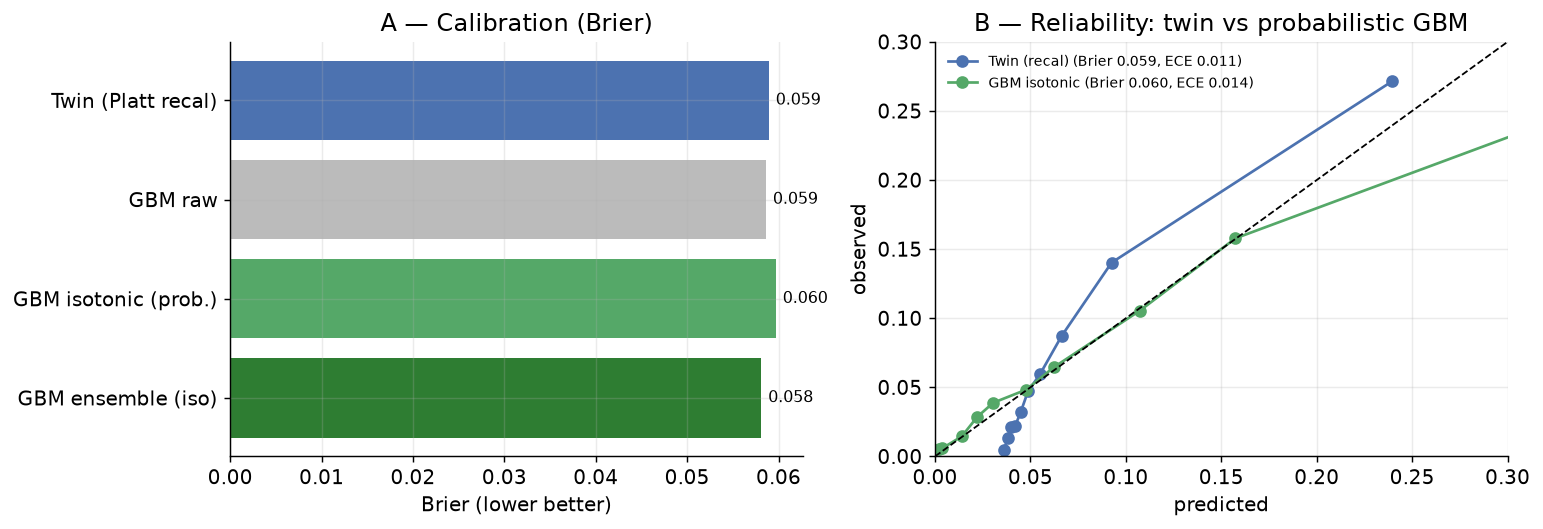

saved to ../outputs/study16_prob_baselines


In [7]:
def rel(p,yy,nb=10):
    b=pd.qcut(p,nb,duplicates="drop"); grp=pd.DataFrame({"p":p,"y":yy}).groupby(b,observed=True); return grp.p.mean().values,grp.y.mean().values
fig,ax=plt.subplots(1,2,figsize=(12,4.2))
y=np.arange(len(tbl)); ax[0].barh(y,tbl.Brier,color=["#4C72B0","#BBBBBB","#55A868","#2E7D32"])
ax[0].set_yticks(y); ax[0].set_yticklabels(tbl.index); ax[0].invert_yaxis()
ax[0].set_xlabel("Brier (lower better)"); ax[0].set_title("A — Calibration (Brier)")
for yi,bv in zip(y,tbl.Brier): ax[0].annotate(f"{bv:.3f}",(bv,yi),xytext=(4,0),textcoords="offset points",va="center",fontsize=9)
mx=0.3
for p,lab,c in [(p_twin,"Twin (recal)","#4C72B0"),(p_gbm_iso,"GBM isotonic","#55A868")]:
    xp,yp=rel(p,yte); ax[1].plot(xp,yp,"-o",label=f"{lab} (Brier {brier(p,yte):.3f}, ECE {ece(p,yte):.3f})",color=c)
ax[1].plot([0,mx],[0,mx],"k--",lw=1); ax[1].set_xlim(0,mx); ax[1].set_ylim(0,mx)
ax[1].set_xlabel("predicted"); ax[1].set_ylabel("observed"); ax[1].set_title("B — Reliability: twin vs probabilistic GBM")
ax[1].legend(fontsize=8,frameon=False)
plt.tight_layout(); plt.savefig(OUT/"s16_fig1_prob_baselines.png",bbox_inches="tight"); plt.show()
print("saved to",OUT)


## Reading this for the reply

- If **GBM isotonic** matches or beats the twin's Brier/ECE, say plainly that calibration is achievable by a
  calibrated discriminative model too, and that the twin's distinctive value is robustness, label-free transfer
  and exact attribution (shown elsewhere), not peak calibration on complete data.
- If the twin's **belief entropy** separates its own errors as well as the **ensemble std** does, that supports
  the claim that the state-space model yields a usable uncertainty signal intrinsically, without an ensemble.
- The GP cell (if enabled) answers the reviewer's specific GP suggestion with a distinct model class; report it as
  a subsampled sanity check, not a full-data number.
